# Proyek Analisis Data
- **Nama Ketua:** Dini Canika Sumara
- **Nama Anggota:**
1. Dian Fatonah
2. Deti Dwi Anugra
3. Dita Ayu Cahaya Apria



### Menentukan Pertanyaan Bisnis
1. Bagaimana tren jumlah anak putus sekolah dari tahun ke tahun di Kota Bandar Lampung?
2. Pada jenjang pendidikan mana jumlah anak putus sekolah paling tinggi setiap tahunnya?
3. Apakah terdapat perbedaan signifikan jumlah anak putus sekolah berdasarkan jenis kelamin?
4. Bagaimana pola distribusi anak putus sekolah berdasarkan kombinasi jenjang dan jenis kelamin sepanjang tahun?
5. Apakah ada tahun tertentu di mana terjadi lonjakan atau penurunan tajam jumlah anak putus sekolah?


## Import Semua Packages/Library yang Digunakan

In [ ]:
# import packages
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from babel.numbers import format_currency
from sklearn.linear_model import LinearRegression

### Data Wrangling

#### Gathering Data

In [ ]:
# import data
dataset_all_df = pd.read_csv('/content/dataset_all.csv')
dataset_all_df

,Kecamatan,Jenjang,Tahun,Jumlah,Jenis Kelamin,Tipe Sekolah,Tingkat
0,Kec. Teluk Betung Barat,SD,2021,0,Laki-laki,Negeri,NaN
1,Kec. Teluk Betung Selatan,SD,2021,0,Laki-laki,Negeri,NaN
2,Kec. Panjang,SD,2021,0,Laki-laki,Negeri,NaN
3,Kec. Tanjung Karang Timur,SD,2021,2,Laki-laki,Negeri,NaN
4,Kec. Teluk Betung Utara,SD,2021,2,Laki-laki,Negeri,NaN
...,...,...,...,...,...,...,...
2739,Kec. Sukabumi,SMK,2024,2,Perempuan,NaN,Total
2740,Kec. Labuhan Ratu,SMK,2024,0,Perempuan,NaN,Total
2741,Kec. Way Halim,SMK,2024,0,Perempuan,NaN,Total
2742,Kec. Enggal,SMK,2024,0,Perempuan,NaN,Total


#### Assesing Data

##### Menilai Tabel dataset_all_df

In [ ]:
dataset_all_df.info()
dataset_all_df.isna().sum()
print("Jumlah Duplikasi: ", dataset_all_df.duplicated().sum())
dataset_all_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2744 entries, 0 to 2743
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Kecamatan      2744 non-null   object
 1   Jenjang        2744 non-null   object
 2   Tahun          2744 non-null   int64 
 3   Jumlah         2744 non-null   int64 
 4   Jenis Kelamin  2744 non-null   object
 5   Tipe Sekolah   480 non-null    object
 6   Tingkat        2264 non-null   object
dtypes: int64(2), object(5)
memory usage: 150.2+ KB
Jumlah Duplikasi:  500


,Tahun,Jumlah
count,2744.000000,2744.000000
mean,2022.495627,0.336006
std,1.122135,1.123475
min,2021.000000,0.000000
25%,2021.000000,0.000000
50%,2022.000000,0.000000
75%,2024.000000,0.000000
max,2024.000000,20.000000


#### Cleaning Data

##### Missing Value

In [ ]:
dataset_all_df.isna().sum()

,0
Kecamatan,0
Jenjang,0
Tahun,0
Jumlah,0
Jenis Kelamin,0
Tipe Sekolah,2264
Tingkat,480


In [ ]:
dataset_all_df['Tipe Sekolah'] = dataset_all_df['Tipe Sekolah'].fillna("Unknown")
print(dataset_all_df.isna().sum())

Kecamatan          0
Jenjang            0
Tahun              0
Jumlah             0
Jenis Kelamin      0
Tipe Sekolah       0
Tingkat          480
dtype: int64


In [ ]:
dataset_all_df.isna().sum()

,0
Kecamatan,0
Jenjang,0
Tahun,0
Jumlah,0
Jenis Kelamin,0
Tipe Sekolah,0
Tingkat,480


##### Duplicate Data

In [ ]:
# Cek jumlah duplikat
duplikat = dataset_all_df.duplicated()
print(f"Jumlah baris duplikat: {duplikat.sum()}")

# Tampilkan contoh duplikat
dataset_all_df[duplikat].head()

Jumlah baris duplikat: 500


,Kecamatan,Jenjang,Tahun,Jumlah,Jenis Kelamin,Tipe Sekolah,Tingkat
1721,Kec. Teluk Betung Selatan,SMK,2021,0,Laki-laki,Unknown,Total
1722,Kec. Panjang,SMK,2021,0,Laki-laki,Unknown,Total
1723,Kec. Tanjung Karang Timur,SMK,2021,0,Laki-laki,Unknown,Total
1725,Kec. Tanjung Karang Pusat,SMK,2021,0,Laki-laki,Unknown,Total
1726,Kec. Tanjung Karang Barat,SMK,2021,0,Laki-laki,Unknown,Total


In [ ]:
# Hapus baris yang benar-benar identik
dataset_all_df_cleaned = dataset_all_df.drop_duplicates()

In [ ]:
print("Jumlah baris sebelum dibersihkan:", len(dataset_all_df))
print("Jumlah baris sesudah dibersihkan:", len(dataset_all_df))
print("Jumlah baris duplikat yang dihapus:", len(dataset_all_df) - len(dataset_all_df_cleaned))


Jumlah baris sebelum dibersihkan: 2744
Jumlah baris sesudah dibersihkan: 2744
Jumlah baris duplikat yang dihapus: 500


In [ ]:
print("Masih ada duplikat penuh?:", dataset_all_df_cleaned.duplicated().any())

Masih ada duplikat penuh?: False


In [ ]:
# Step 1: Pembersihan Data
dataset_all_df = dataset_all_df.drop_duplicates()
dataset_model_df = dataset_all_df.drop(columns=['Tipe Sekolah', 'Tingkat'])


### Exploratory Data Analysis (EDA)

In [ ]:
# -------------------------------------
# Import libraries
# -------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

In [ ]:
# -------------------------------------
# Load dan bersihkan data
# -------------------------------------
df = pd.read_csv('/content/dataset_all.csv')
df['Tipe Sekolah'] = df['Tipe Sekolah'].fillna("Unknown")
df = df.drop_duplicates()

In [ ]:
# Info data
print(df.info())
print(df.describe())
print(df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 2244 entries, 0 to 2727
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Kecamatan      2244 non-null   object
 1   Jenjang        2244 non-null   object
 2   Tahun          2244 non-null   int64 
 3   Jumlah         2244 non-null   int64 
 4   Jenis Kelamin  2244 non-null   object
 5   Tipe Sekolah   2244 non-null   object
 6   Tingkat        1764 non-null   object
dtypes: int64(2), object(5)
memory usage: 140.2+ KB
None
             Tahun       Jumlah
count  2244.000000  2244.000000
mean   2022.498663     0.390820
std       1.120274     1.223607
min    2021.000000     0.000000
25%    2021.000000     0.000000
50%    2022.500000     0.000000
75%    2024.000000     0.000000
max    2024.000000    20.000000
Kecamatan          0
Jenjang            0
Tahun              0
Jumlah             0
Jenis Kelamin      0
Tipe Sekolah       0
Tingkat          480
dtype: int64


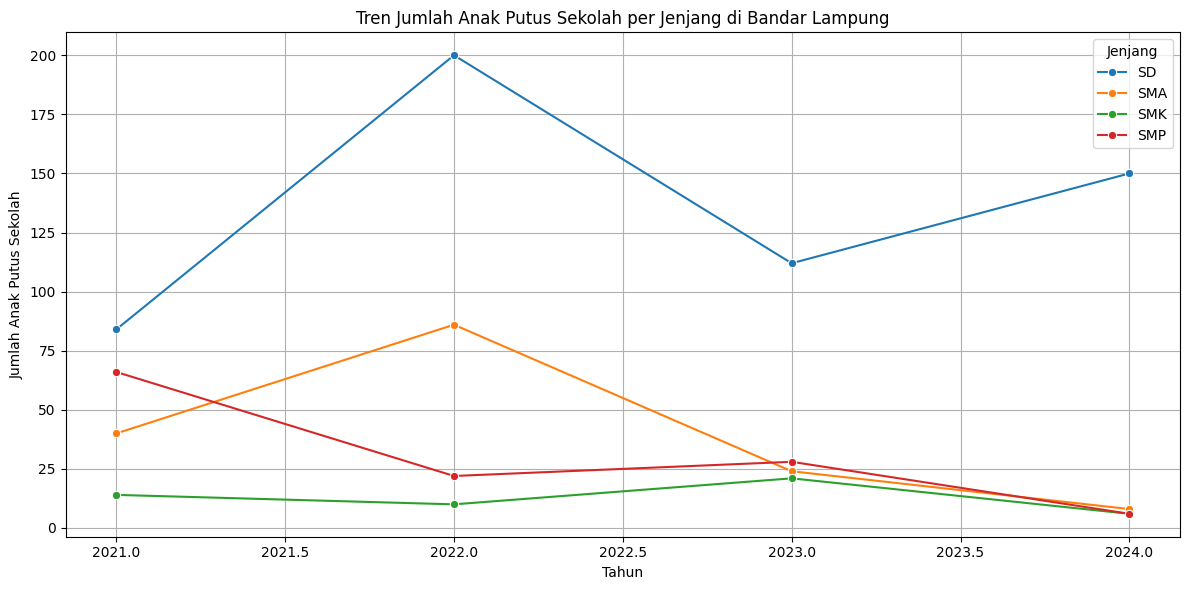

In [ ]:
# -------------------------------------
# [Q1] Tren jumlah anak putus sekolah dari tahun ke tahun di tiap jenjang
# -------------------------------------
total_pertahun = df.groupby(['Tahun', 'Jenjang'])['Jumlah'].sum().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=total_pertahun, x='Tahun', y='Jumlah', hue='Jenjang', marker='o')
plt.title("Tren Jumlah Anak Putus Sekolah per Jenjang di Bandar Lampung")
plt.ylabel("Jumlah Anak Putus Sekolah")
plt.grid(True)
plt.tight_layout()
plt.show()

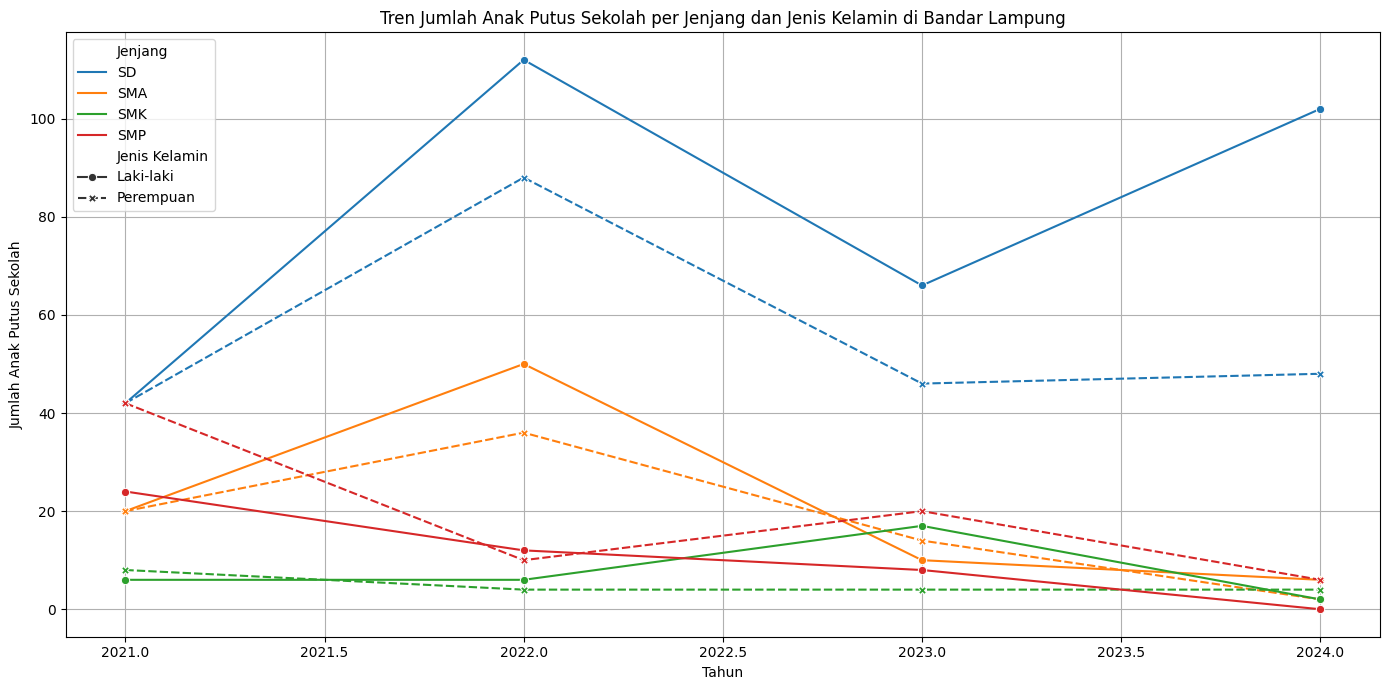

In [ ]:
# Grup berdasarkan Tahun, Jenjang, dan Jenis Kelamin
total_pertahun_gender = df.groupby(['Tahun', 'Jenjang', 'Jenis Kelamin'])['Jumlah'].sum().reset_index()

plt.figure(figsize=(14, 7))
sns.lineplot(data=total_pertahun_gender, x='Tahun', y='Jumlah', hue='Jenjang', style='Jenis Kelamin', markers=True)
plt.title("Tren Jumlah Anak Putus Sekolah per Jenjang dan Jenis Kelamin di Bandar Lampung")
plt.ylabel("Jumlah Anak Putus Sekolah")
plt.xlabel("Tahun")
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# -------------------------------------
# [Q2] Jenjang pendidikan dengan jumlah anak putus sekolah paling tinggi tiap tahunnya
# -------------------------------------
max_jenjang_per_year = total_pertahun.loc[total_pertahun.groupby("Tahun")["Jumlah"].idxmax()]
print("Jenjang dengan jumlah putus sekolah tertinggi setiap tahunnya:\n", max_jenjang_per_year)


Jenjang dengan jumlah putus sekolah tertinggi setiap tahunnya:
     Tahun Jenjang  Jumlah
0    2021      SD      84
4    2022      SD     200
8    2023      SD     112
12   2024      SD     150


In [ ]:
# -------------------------------------
# [Regresi] Model regresi linear per jenjang + evaluasi (MAE & R²)
# -------------------------------------
def run_regression(jenjang):
    df_jenjang = total_pertahun[total_pertahun['Jenjang'] == jenjang]
    X = df_jenjang[['Tahun']]
    y = df_jenjang['Jumlah']

    model = LinearRegression()
    model.fit(X, y)
    y_pred = model.predict(X)

    mae = mean_absolute_error(y, y_pred)
    r2 = r2_score(y, y_pred)

    plt.figure(figsize=(8, 4))
    plt.plot(X, y, marker='o', label='Aktual')
    plt.plot(X, y_pred, linestyle='--', color='red', label='Prediksi')
    plt.title(f'Regresi Linear - {jenjang} | MAE: {mae:.2f}, R²: {r2:.2f}')
    plt.xlabel('Tahun')
    plt.ylabel('Jumlah Anak Putus Sekolah')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    return mae, r2


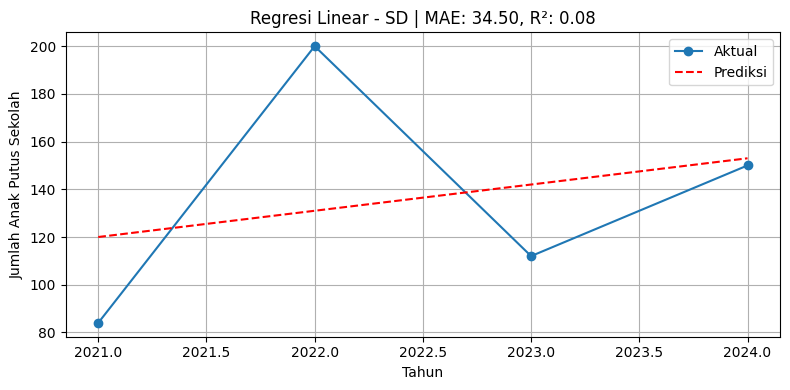

Jenjang: SD → MAE: 34.50, R²: 0.08


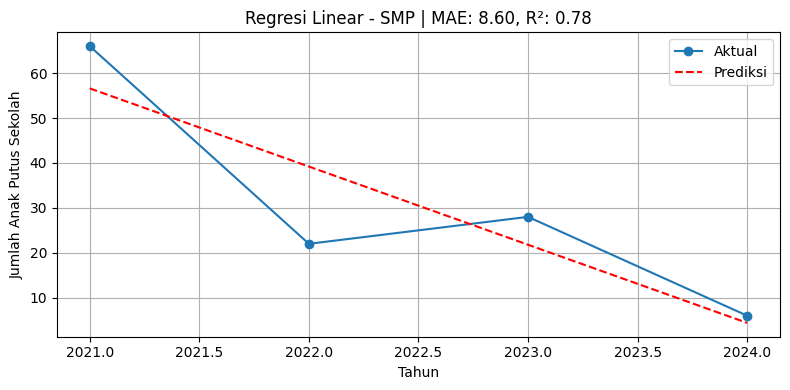

Jenjang: SMP → MAE: 8.60, R²: 0.78


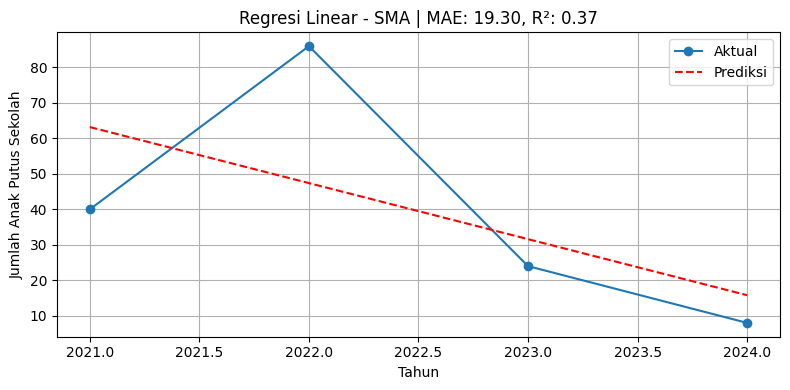

Jenjang: SMA → MAE: 19.30, R²: 0.37


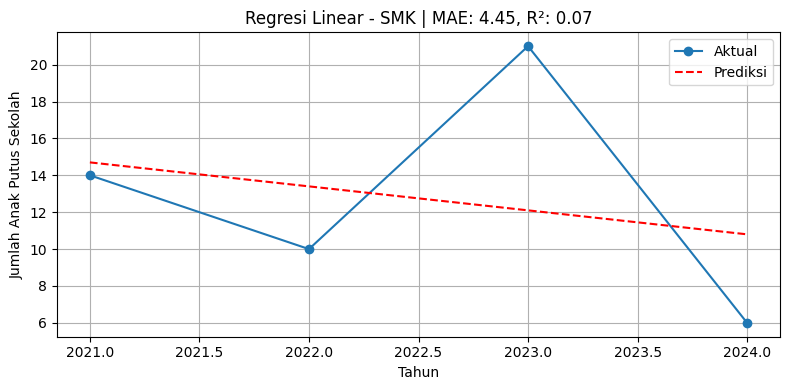

Jenjang: SMK → MAE: 4.45, R²: 0.07


In [ ]:
# Uji regresi untuk tiap jenjang
for jenjang in df['Jenjang'].unique():
    mae, r2 = run_regression(jenjang)
    print(f"Jenjang: {jenjang} → MAE: {mae:.2f}, R²: {r2:.2f}")

   Tahun  Jumlah  Prediksi  Selisih
0   2021     218     268.6    -50.6
1   2022     328     243.2     84.8
2   2023     200     217.8    -17.8
3   2024     176     192.4    -16.4


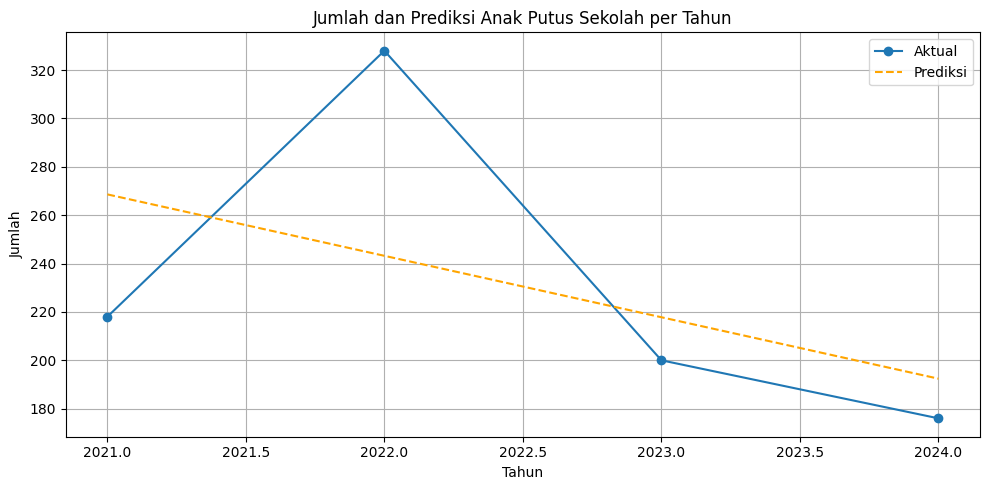

In [ ]:
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
import matplotlib.pyplot as plt

# Load data
df = pd.read_csv('/content/dataset_all.csv')

# Bersihkan data: pastikan 'Jumlah' dan 'Tahun' bertipe numerik dan tidak null
df['Jumlah'] = pd.to_numeric(df['Jumlah'], errors='coerce')
df['Tahun'] = pd.to_numeric(df['Tahun'], errors='coerce')
df = df.dropna(subset=['Jumlah', 'Tahun'])

# Grouping seperti Power BI: total semua jumlah per tahun (tanpa filter)
total_per_tahun = df.groupby('Tahun')['Jumlah'].sum().reset_index()

# Regresi Linear
X_all = total_per_tahun[['Tahun']]
y_all = total_per_tahun['Jumlah']
model_all = LinearRegression().fit(X_all, y_all)
y_pred_all = model_all.predict(X_all)

# Tambahkan prediksi dan selisih ke dataframe
total_per_tahun['Prediksi'] = y_pred_all
total_per_tahun['Selisih'] = total_per_tahun['Jumlah'] - total_per_tahun['Prediksi']

# Tampilkan hasil
print(total_per_tahun)

# Plot hasil
plt.figure(figsize=(10, 5))
plt.plot(X_all, y_all, marker='o', label='Aktual')
plt.plot(X_all, y_pred_all, linestyle='--', color='orange', label='Prediksi')
plt.title('Jumlah dan Prediksi Anak Putus Sekolah per Tahun')
plt.xlabel('Tahun')
plt.ylabel('Jumlah')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


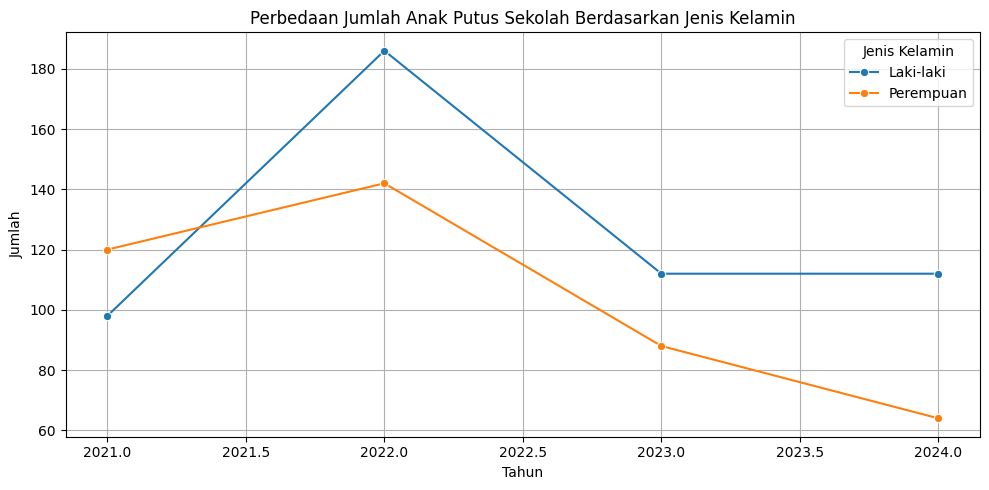

In [ ]:
# -------------------------------------
# [Q3] Perbedaan jumlah anak putus sekolah berdasarkan jenis kelamin
# -------------------------------------
gender_yearly = df.groupby(['Tahun', 'Jenis Kelamin'])['Jumlah'].sum().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(data=gender_yearly, x='Tahun', y='Jumlah', hue='Jenis Kelamin', marker='o')
plt.title("Perbedaan Jumlah Anak Putus Sekolah Berdasarkan Jenis Kelamin")
plt.ylabel("Jumlah")
plt.grid(True)
plt.tight_layout()
plt.show()

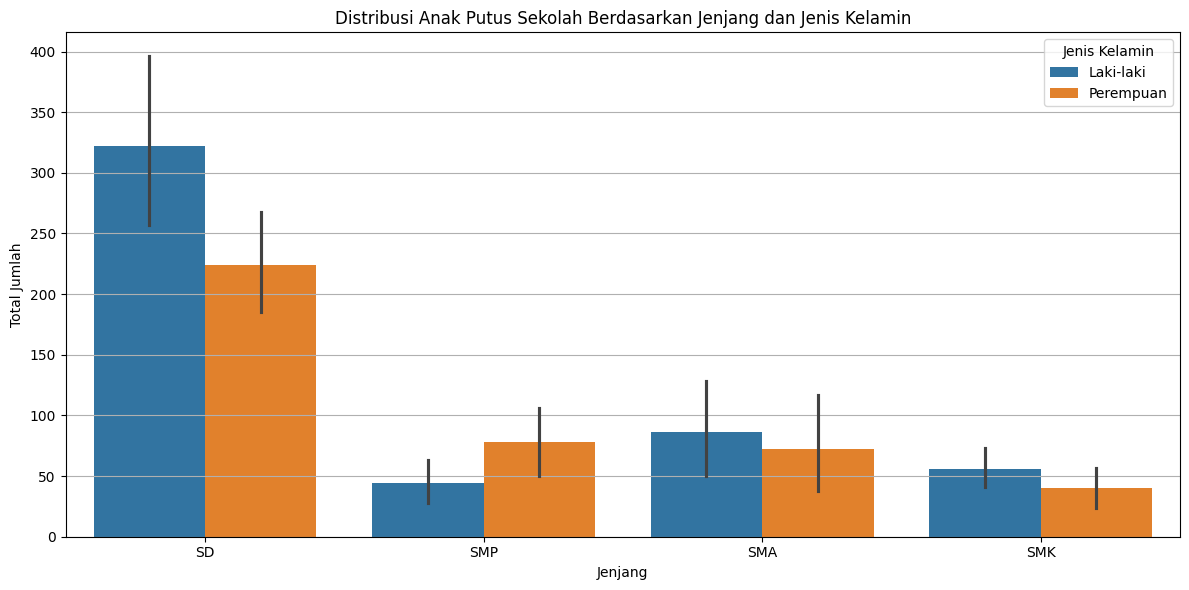

In [ ]:
# -------------------------------------
# [Q4] Pola distribusi berdasarkan kombinasi Jenjang & Jenis Kelamin
# -------------------------------------
plt.figure(figsize=(12, 6))
sns.barplot(data=df, x='Jenjang', y='Jumlah', hue='Jenis Kelamin', estimator=sum)
plt.title("Distribusi Anak Putus Sekolah Berdasarkan Jenjang dan Jenis Kelamin")
plt.ylabel("Total Jumlah")
plt.grid(True, axis='y')
plt.tight_layout()
plt.show()

In [ ]:
# Hitung total jumlah anak putus sekolah berdasarkan Jenjang dan Jenis Kelamin
jumlah_per_jenjang_gender = df.groupby(['Jenjang', 'Jenis Kelamin'])['Jumlah'].sum().reset_index()

# Tampilkan hasilnya
print(jumlah_per_jenjang_gender)


  Jenjang Jenis Kelamin  Jumlah
0      SD     Laki-laki     322
1      SD     Perempuan     224
2     SMA     Laki-laki      86
3     SMA     Perempuan      72
4     SMK     Laki-laki      56
5     SMK     Perempuan      40
6     SMP     Laki-laki      44
7     SMP     Perempuan      78


<ipython-input-68-873748569>:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Tahun', y='Delta', data=df_total_per_year, palette='coolwarm')


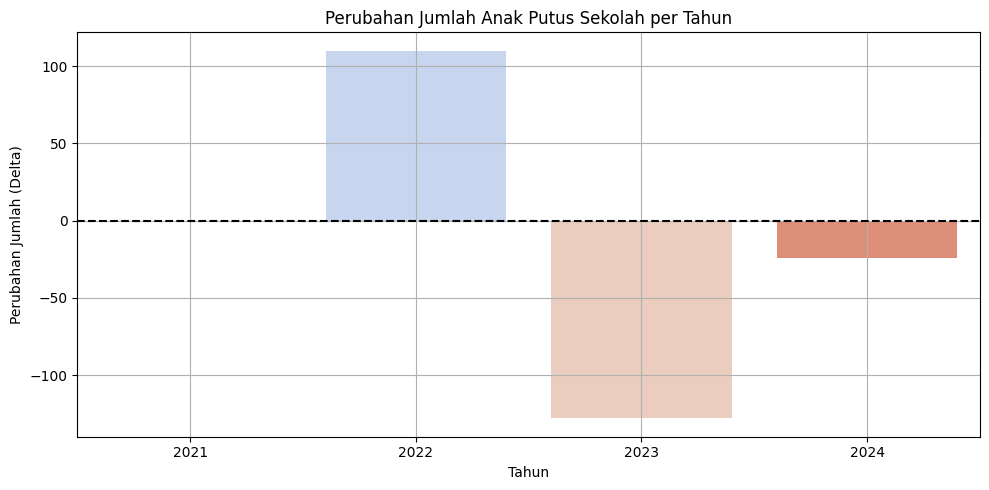

In [ ]:
# -------------------------------------
# [Q5] Tahun dengan lonjakan atau penurunan tajam
# -------------------------------------
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Asumsikan df sudah didefinisikan dan berisi kolom 'Tahun' dan 'Jumlah'

# 1. Group by Tahun
total_semua = df.groupby('Tahun')['Jumlah'].sum().reset_index()

# 2. Hitung perubahan tahunan (Delta)
df_total_per_year = total_semua.copy()
df_total_per_year['Delta'] = df_total_per_year['Jumlah'].diff()

# 3. Visualisasi perubahan (lonjakan/penurunan)
plt.figure(figsize=(10, 5))
sns.barplot(x='Tahun', y='Delta', data=df_total_per_year, palette='coolwarm')
plt.axhline(0, color='black', linestyle='--')
plt.title("Perubahan Jumlah Anak Putus Sekolah per Tahun")
plt.ylabel("Perubahan Jumlah (Delta)")
plt.grid(True)
plt.tight_layout()
plt.show()


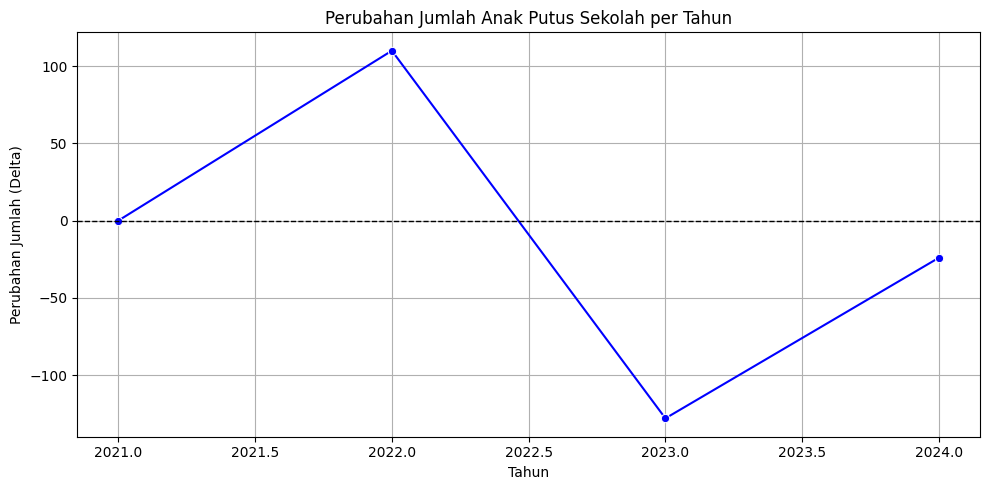

In [ ]:
df_total_per_year = total_semua.copy()
df_total_per_year['Delta'] = df_total_per_year['Jumlah'].diff()

# Ganti NaN pada baris pertama Delta jadi 0
df_total_per_year['Delta'] = df_total_per_year['Delta'].fillna(0)

# Pastikan Tahun bertipe integer
df_total_per_year['Tahun'] = df_total_per_year['Tahun'].astype(int)

plt.figure(figsize=(10, 5))
sns.lineplot(x='Tahun', y='Delta', data=df_total_per_year, marker='o', color='blue')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title("Perubahan Jumlah Anak Putus Sekolah per Tahun")
plt.ylabel("Perubahan Jumlah (Delta)")
plt.xlabel("Tahun")
plt.grid(True)
plt.tight_layout()
plt.show()




In [ ]:
print(df_total_per_year[['Tahun', 'Jumlah', 'Delta']])


   Tahun  Jumlah  Delta
0   2021     218    0.0
1   2022     328  110.0
2   2023     200 -128.0
3   2024     176  -24.0


In [ ]:
# Tampilkan tahun dengan perubahan tertinggi
max_increase = df_total_per_year[df_total_per_year['Delta'] == df_total_per_year['Delta'].max()]
max_decrease = df_total_per_year[df_total_per_year['Delta'] == df_total_per_year['Delta'].min()]
print("Lonjakan terbesar:\n", max_increase)
print("Penurunan terbesar:\n", max_decrease)

Lonjakan terbesar:
    Tahun  Jumlah  Delta
1   2022     328  110.0
Penurunan terbesar:
    Tahun  Jumlah  Delta
2   2023     200 -128.0
